> **Versi arsip ARIMAX-GARCH** (`arsip/arimax_garch/`, terpisah dari skripsi). Ada model kelima,
> ARIMAX-GARCH, yang meramal langsung dari persamaan mean ARIMAX.

# 03 Perbandingan Model

Notebook ini menggabungkan prediksi kelima model pada 305 hari data testing untuk setiap
emiten. Prediksi LSTM, GRU, GARCH-LSTM, dan GARCH-GRU dibaca dari sheet `prediksi` di
`outputs/02_{M}_{E}.xlsx`, dan prediksi ARIMAX-GARCH dari sheet `prediksi_arimax_garch` di
`outputs/01_arimax_garch_{E}.xlsx`. Tidak ada pelatihan ulang dan tidak ada agregat.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

BERKAS_XLSX = "outputs/03_perbandingan.xlsx"
EMITEN_LIST = ["ANTM", "INCO"]
MODEL_LIST = ["LSTM", "GRU", "GARCH-LSTM", "GARCH-GRU", "ARIMAX-GARCH"]
WARNA = {"LSTM": "tab:green", "GRU": "tab:purple", "GARCH-LSTM": "tab:orange", "GARCH-GRU": "tab:red",
         "ARIMAX-GARCH": "tab:brown"}
tabel = {}   # seluruh tabel yang disimpan ke xlsx

def tampil(df):
    # tampilkan 10 baris teratas dan 10 baris terbawah
    if len(df) <= 20:
        display(df)
    else:
        display(pd.concat([df.head(10), df.tail(10)]))

## 1. Gabungan prediksi

Satu tabel per emiten: tanggal, harga aktual, dan prediksi kelima model. Tanggal
dan harga aktual diperiksa harus sama pada kelima berkas.

In [2]:
for e in EMITEN_LIST:
    gabungan = None
    for m in MODEL_LIST:
        if m == "ARIMAX-GARCH":
            pred = pd.read_excel("outputs/01_arimax_garch_" + e + ".xlsx", sheet_name="prediksi_arimax_garch")
        else:
            pred = pd.read_excel("outputs/02_" + m + "_" + e + ".xlsx", sheet_name="prediksi")
        if gabungan is None:
            gabungan = pred[["Tanggal", "aktual"]].copy()
        assert (pred["Tanggal"] == gabungan["Tanggal"]).all()
        assert (pred["aktual"] == gabungan["aktual"]).all()
        gabungan[m] = pred["prediksi"]
    assert len(gabungan) == 305
    tabel["prediksi_gabungan_" + e] = gabungan
    print(e)
    tampil(gabungan)

ANTM


,Tanggal,aktual,LSTM,GRU,GARCH-LSTM,GARCH-GRU,ARIMAX-GARCH
0,2025-01-13,1480,1511.959961,1476.502686,1443.852417,1474.989014,1461.935298
1,2025-01-14,1520,1529.665039,1490.927490,1442.071899,1482.585571,1473.600502
2,2025-01-15,1530,1563.548584,1516.289185,1445.671753,1498.887451,1522.073515
3,2025-01-16,1520,1596.690674,1536.974731,1455.039551,1517.151733,1538.831365
4,2025-01-17,1520,1616.225098,1544.566528,1462.636108,1528.593994,1534.854816
5,2025-01-20,1510,1623.484375,1544.964600,1466.353149,1534.469116,1525.938907
6,2025-01-21,1510,1618.251099,1539.810059,1466.065430,1534.073608,1511.296074
7,2025-01-22,1520,1612.955811,1539.137329,1467.875366,1533.843384,1519.051305
8,2025-01-23,1490,1610.864746,1540.500732,1468.422485,1534.513184,1518.531673
9,2025-01-24,1490,1594.936768,1528.426758,1460.999390,1526.266846,1483.243744


INCO


,Tanggal,aktual,LSTM,GRU,GARCH-LSTM,GARCH-GRU,ARIMAX-GARCH
0,2025-01-13,3430,3467.939697,3487.419922,3588.775635,3488.876709,3434.854682
1,2025-01-14,3680,3477.757568,3496.348389,3586.670166,3495.836426,3435.909713
2,2025-01-15,3650,3620.436279,3623.343262,3644.470215,3624.632324,3692.765581
3,2025-01-16,3590,3672.741699,3680.615479,3698.889893,3681.092773,3644.893199
4,2025-01-17,3570,3655.423584,3671.837402,3725.077148,3666.852783,3590.743327
5,2025-01-20,3580,3628.523682,3648.020020,3730.534912,3641.465332,3572.470143
6,2025-01-21,3580,3618.194824,3637.283936,3726.777344,3631.363037,3579.594142
7,2025-01-22,3540,3615.686768,3634.119873,3720.286377,3627.975586,3580.759287
8,2025-01-23,3420,3588.916992,3611.820068,3703.434082,3605.140137,3530.264548
9,2025-01-24,3210,3510.179932,3540.883301,3662.212158,3534.059814,3412.235854


In [3]:
# metrik data testing kelima model per emiten, dibaca dari sheet metrik notebook 02 (ARIMAX-GARCH: notebook 01)
for e in EMITEN_LIST:
    baris = []
    for m in MODEL_LIST:
        if m == "ARIMAX-GARCH":
            metrik = pd.read_excel("outputs/01_arimax_garch_" + e + ".xlsx", sheet_name="metrik")
        else:
            metrik = pd.read_excel("outputs/02_" + m + "_" + e + ".xlsx", sheet_name="metrik")
        baris.append([m, metrik["rmse"][0], metrik["mae"][0], metrik["mape"][0]])
    perbandingan_metrik = pd.DataFrame(baris, columns=["model", "rmse", "mae", "mape"])
    tabel["metrik_" + e] = perbandingan_metrik
    print(e)
    display(perbandingan_metrik)

ANTM


,model,rmse,mae,mape
0,LSTM,132.684296,103.442266,3.730670
1,GRU,530.870076,431.949007,12.710269
2,GARCH-LSTM,550.010407,443.568595,13.376854
3,GARCH-GRU,504.268524,393.887328,11.490222
4,ARIMAX-GARCH,105.945289,77.651074,2.581570


INCO

,model,rmse,mae,mape
0,LSTM,231.737442,169.984478,4.130564
1,GRU,277.520980,204.206251,4.876553
2,GARCH-LSTM,282.827830,211.259100,5.157463
3,GARCH-GRU,262.795109,193.164487,4.605177
4,ARIMAX-GARCH,175.352506,123.168232,2.886486


## 2. Grafik perbandingan

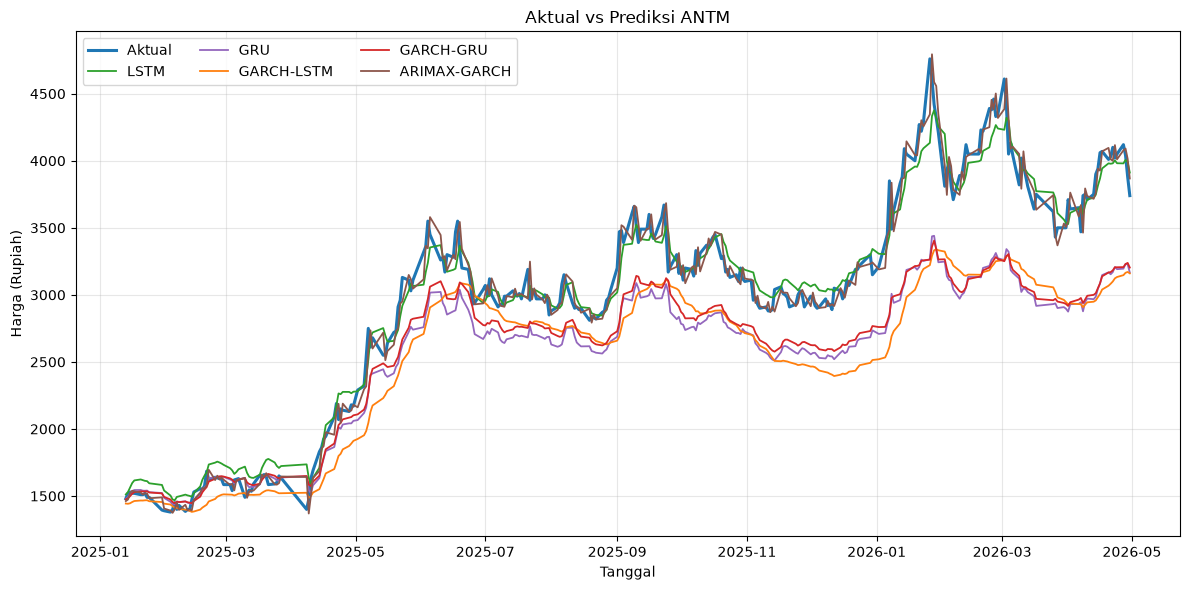

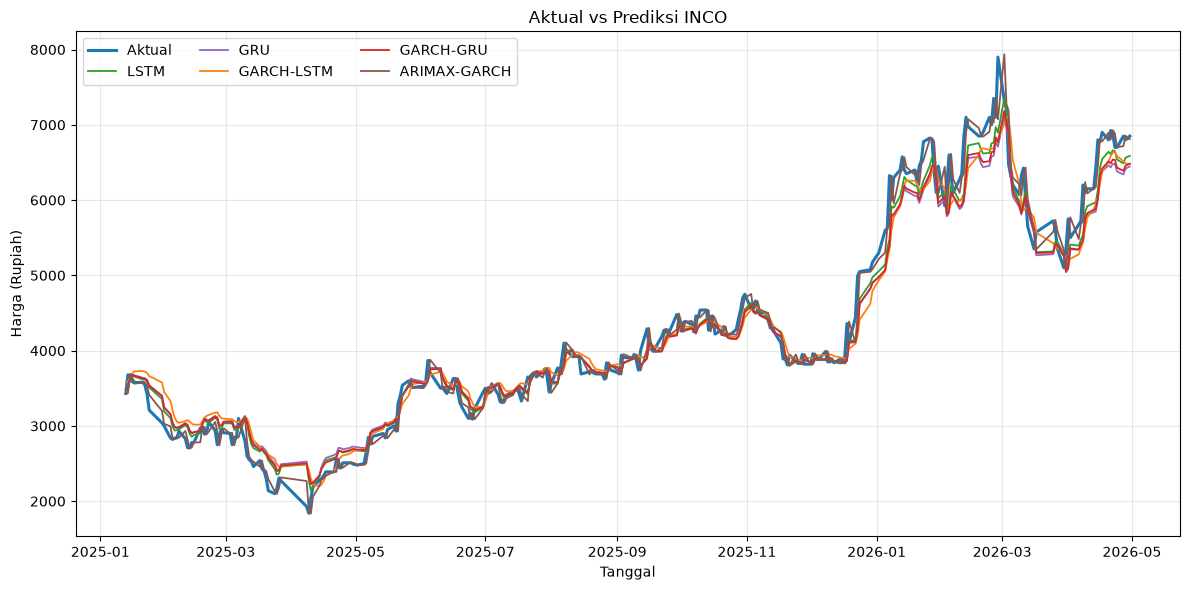

In [4]:
for e in EMITEN_LIST:
    gabungan = tabel["prediksi_gabungan_" + e]
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.plot(gabungan["Tanggal"], gabungan["aktual"], color="tab:blue", lw=2.2, label="Aktual")
    for m in MODEL_LIST:
        ax.plot(gabungan["Tanggal"], gabungan[m], color=WARNA[m], lw=1.3, label=m)
    ax.set_title("Aktual vs Prediksi " + e)
    ax.set_xlabel("Tanggal")
    ax.set_ylabel("Harga (Rupiah)")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left", ncol=3)
    plt.tight_layout()
    plt.savefig("outputs/gambar_perbandingan_" + e + ".png", dpi=300)
    plt.show()

## 3. Simpan tabel

In [5]:
with pd.ExcelWriter(BERKAS_XLSX, date_format="YYYY-MM-DD", datetime_format="YYYY-MM-DD") as writer:
    for nama_sheet in tabel:
        tabel[nama_sheet].to_excel(writer, sheet_name=nama_sheet, index=False)